# Task 37: k-NN Elbow Method

Compare odd k values with stratified 5-fold validation. The plot shows fold-mean error and standard error; the chosen k is the smallest value within one standard error of the minimum.

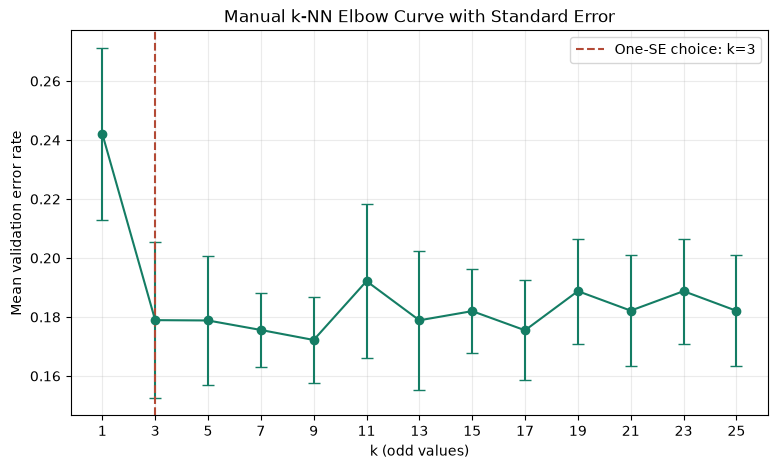

Unique records evaluated: 302
Lowest mean error: k=9, error=0.1722
One-standard-error selection: k=3; cutoff=0.1867


,1,3,5,7,9,11,13,15,17,19,21,23,25
mean_error,0.242106,0.178926,0.178814,0.175594,0.172202,0.19215,0.178871,0.181984,0.175481,0.188762,0.18215,0.188762,0.182093
standard_error,0.029096,0.026397,0.021774,0.012568,0.014459,0.026069,0.023561,0.01432,0.016937,0.017796,0.018795,0.017796,0.018788
fold_errors,"[0.29508196721311475, 0.18032786885245902, 0.1...","[0.2459016393442623, 0.13114754098360656, 0.11...","[0.22950819672131148, 0.13114754098360656, 0.1...","[0.21311475409836064, 0.14754098360655737, 0.1...","[0.18032786885245902, 0.18032786885245902, 0.1...","[0.18032786885245902, 0.22950819672131148, 0.1...","[0.14754098360655737, 0.2459016393442623, 0.11...","[0.16393442622950818, 0.22950819672131148, 0.1...","[0.16393442622950818, 0.21311475409836064, 0.1...","[0.19672131147540983, 0.21311475409836064, 0.1...","[0.19672131147540983, 0.21311475409836064, 0.1...","[0.19672131147540983, 0.21311475409836064, 0.1...","[0.18032786885245902, 0.21311475409836064, 0.1..."


In [2]:
from pathlib import Path
import heapq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

candidates = [Path("heart.csv"), Path("Task_37_KNN_Elbow_Method/heart.csv"), Path("Heart_Disease_Tasks/Task_37_KNN_Elbow_Method/heart.csv")]
csv_path = next(path for path in candidates if path.is_file())
data = pd.read_csv(csv_path).drop_duplicates().reset_index(drop=True)
feature_names = [name for name in ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal"] if name in data.columns]
X = data[feature_names].to_numpy(dtype=float)
y = data["target"].to_numpy(dtype=int)


def make_stratified_folds(labels, fold_count=5, seed=37):
    rng = np.random.default_rng(seed)
    folds = [[] for _ in range(fold_count)]
    for label in np.unique(labels):
        indices = np.flatnonzero(labels == label)
        rng.shuffle(indices)
        for fold_index, part in enumerate(np.array_split(indices, fold_count)):
            folds[fold_index].extend(part.tolist())
    return [np.array(sorted(part), dtype=int) for part in folds]


class KDTree:
    def __init__(self, points, leaf_size=16):
        self.points = np.asarray(points, dtype=float)
        self.leaf_size = leaf_size
        self.root = self._build(np.arange(len(self.points)))

    def _build(self, indices):
        subset = self.points[indices]
        low, high = subset.min(axis=0), subset.max(axis=0)
        node = {"low": low, "high": high}
        if len(indices) <= self.leaf_size:
            node["indices"] = indices
            return node
        axis = int(np.argmax(high - low))
        order = indices[np.argsort(self.points[indices, axis], kind="mergesort")]
        middle = len(order) // 2
        node["left"], node["right"] = self._build(order[:middle]), self._build(order[middle:])
        return node

    @staticmethod
    def _box_distance_squared(point, node):
        delta = np.maximum(np.maximum(node["low"] - point, point - node["high"]), 0.0)
        return float(delta @ delta)

    def query(self, point, k):
        heap = []
        def visit(node):
            if len(heap) == k and self._box_distance_squared(point, node) > -heap[0][0]:
                return
            if "indices" in node:
                for index in node["indices"]:
                    delta = point - self.points[index]
                    distance_squared = float(delta @ delta)
                    item = (-distance_squared, -int(index), int(index))
                    if len(heap) < k:
                        heapq.heappush(heap, item)
                    elif item > heap[0]:
                        heapq.heapreplace(heap, item)
                return
            children = [node["left"], node["right"]]
            children.sort(key=lambda child: self._box_distance_squared(point, child))
            visit(children[0])
            visit(children[1])
        visit(self.root)
        ordered = sorted(heap, key=lambda item: (-item[0], item[2]))
        indices = np.array([item[2] for item in ordered], dtype=int)
        distances = np.sqrt(np.array([-item[0] for item in ordered]))
        return indices, distances


def vote(labels, distances):
    classes, counts = np.unique(labels, return_counts=True)
    tied = classes[counts == counts.max()]
    if len(tied) == 1:
        return int(tied[0])
    totals = {int(label): float(distances[labels == label].sum()) for label in tied}
    best_total = min(totals.values())
    tied = [label for label in tied if np.isclose(totals[label], best_total)]
    return int(labels[0]) if labels[0] in tied else min(tied)


candidate_ks = list(range(1, 26, 2))
folds = make_stratified_folds(y, fold_count=5)
fold_errors = {k: [] for k in candidate_ks}
for test_indices in folds:
    test_set = set(test_indices.tolist())
    train_indices = np.array([i for i in range(len(y)) if i not in test_set], dtype=int)
    X_train, X_test = X[train_indices], X[test_indices]
    y_train, y_test = y[train_indices], y[test_indices]
    means, scales = X_train.mean(axis=0), X_train.std(axis=0)
    scales[scales == 0] = 1.0
    X_train, X_test = (X_train - means) / scales, (X_test - means) / scales
    tree = KDTree(X_train)
    fold_wrong = {k: 0 for k in candidate_ks}
    for row, actual in zip(X_test, y_test):
        neighbor_indices, neighbor_distances = tree.query(row, max(candidate_ks))
        labels = y_train[neighbor_indices]
        for k in candidate_ks:
            fold_wrong[k] += int(vote(labels[:k], neighbor_distances[:k]) != actual)
    for k in candidate_ks:
        fold_errors[k].append(fold_wrong[k] / len(test_indices))

mean_errors = {k: float(np.mean(fold_errors[k])) for k in candidate_ks}
standard_errors = {k: float(np.std(fold_errors[k], ddof=1) / np.sqrt(len(folds))) for k in candidate_ks}
minimum_k = min(candidate_ks, key=mean_errors.get)
cutoff = mean_errors[minimum_k] + standard_errors[minimum_k]
selected_k = min(k for k in candidate_ks if mean_errors[k] <= cutoff)

fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(candidate_ks, [mean_errors[k] for k in candidate_ks], yerr=[standard_errors[k] for k in candidate_ks], marker="o", capsize=4, color="#147d64")
ax.axvline(selected_k, color="#b34a36", linestyle="--", label=f"One-SE choice: k={selected_k}")
ax.set_xlabel("k (odd values)")
ax.set_ylabel("Mean validation error rate")
ax.set_title("Manual k-NN Elbow Curve with Standard Error")
ax.set_xticks(candidate_ks)
ax.grid(True, alpha=0.25)
ax.legend()
plt.show()
print(f"Unique records evaluated: {len(data)}")
print(f"Lowest mean error: k={minimum_k}, error={mean_errors[minimum_k]:.4f}")
print(f"One-standard-error selection: k={selected_k}; cutoff={cutoff:.4f}")
pd.DataFrame({"mean_error": mean_errors, "standard_error": standard_errors, "fold_errors": fold_errors}).T